# 02 — Feature Importance: Format Features
## Which format-specific features predict performance?

In [1]:
import sys, json, warnings
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_score
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (14, 6)

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

df = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'format_dataset.parquet')
with open(PROJECT_ROOT / 'format_features_reference.json', 'r', encoding='utf-8') as f:
    ref = json.load(f)

format_features = [feat['name'] for feat in ref['features']]
available = [f for f in format_features if f in df.columns]
print(f'Dataset: {df.shape[0]} posts, {len(available)} format features available')

Dataset: 140 posts, 15 format features available


In [2]:
def encode_features(df, feature_list):
    """Label-encode categorical columns, coerce numeric, drop rows with NaN."""
    X = df[feature_list].copy()
    encoders = {}
    for col in X.columns:
        numeric = pd.to_numeric(X[col], errors='coerce')
        if numeric.notna().sum() > len(X) * 0.5:
            X[col] = numeric
        else:
            le = LabelEncoder()
            X[col] = X[col].astype(str)
            X[col] = le.fit_transform(X[col])
            encoders[col] = le
    X = X.fillna(X.median())
    return X, encoders

X_format, encoders = encode_features(df, available)
print(f'Feature matrix: {X_format.shape}')

Feature matrix: (140, 15)


## Random Forest Feature Importance per Metric

In [3]:
targets = ['reach', 'views', 'likes', 'shares', 'saved']
available_targets = [t for t in targets if t in df.columns]

importance_results = {}

for target in available_targets:
    y = pd.to_numeric(df[target], errors='coerce')
    mask = y.notna() & X_format.notna().all(axis=1)
    X_clean = X_format[mask]
    y_clean = y[mask]

    rf = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1)
    rf.fit(X_clean, y_clean)

    imp = pd.Series(rf.feature_importances_, index=available).sort_values(ascending=False)
    importance_results[target] = imp

    cv_scores = cross_val_score(rf, X_clean, y_clean, cv=5, scoring='r2')
    print(f'\n{target.upper()} — RF R²: {cv_scores.mean():.3f} (±{cv_scores.std():.3f})')
    print(f'  Top 5: {list(imp.head(5).index)}')


REACH — RF R²: -88.193 (±175.216)
  Top 5: ['call_to_action_quality', 'audience_familiarity_with_subject', 'presenter_energy_level', 'pop_culture_focus', 'presenter_combination']



VIEWS — RF R²: -58.027 (±114.729)
  Top 5: ['call_to_action_quality', 'presenter_energy_level', 'audience_familiarity_with_subject', 'pop_culture_focus', 'plot_twist_strength']



LIKES — RF R²: -317.938 (±635.112)
  Top 5: ['call_to_action_quality', 'presenter_energy_level', 'audience_familiarity_with_subject', 'pop_culture_focus', 'plot_twist_strength']



SHARES — RF R²: -27.486 (±52.921)
  Top 5: ['call_to_action_quality', 'audience_familiarity_with_subject', 'pop_culture_focus', 'presenter_energy_level', 'plot_twist_strength']



SAVED — RF R²: -37.099 (±72.473)
  Top 5: ['call_to_action_quality', 'presenter_energy_level', 'pop_culture_focus', 'audience_familiarity_with_subject', 'visual_relevance']


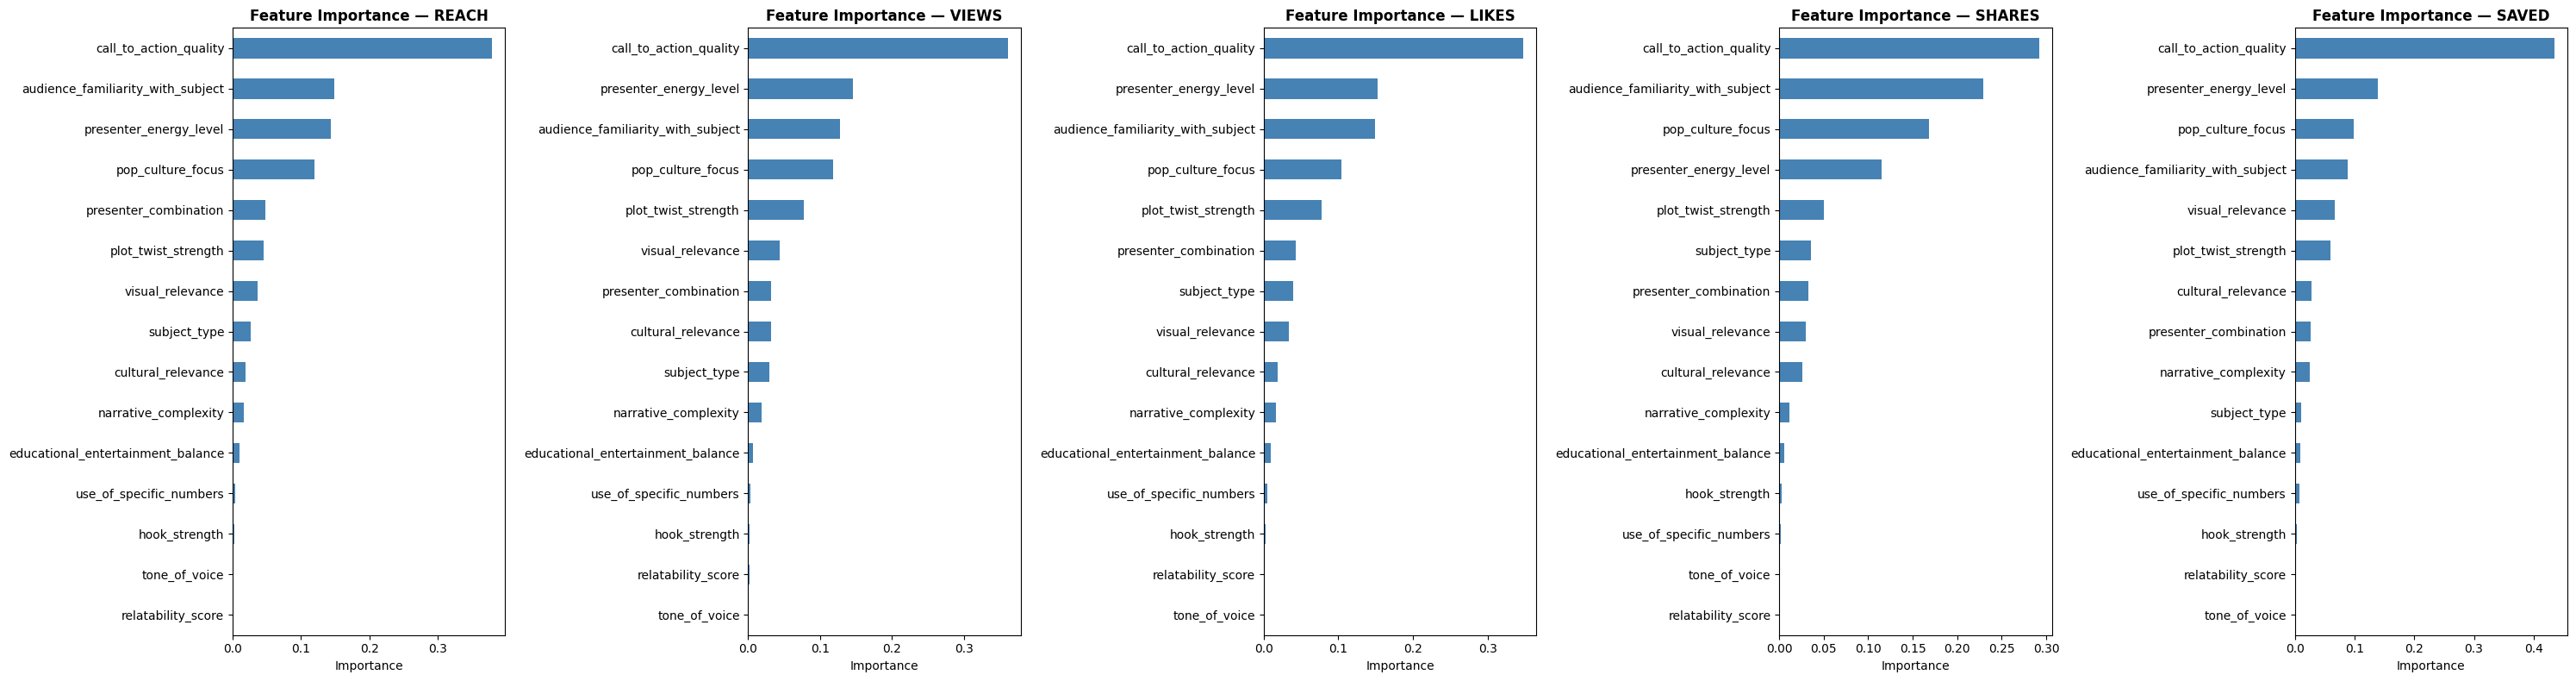

In [4]:
n_targets = len(available_targets)
fig, axes = plt.subplots(1, n_targets, figsize=(6 * n_targets, 8))
if n_targets == 1:
    axes = [axes]

for ax, target in zip(axes, available_targets):
    imp = importance_results[target].sort_values(ascending=True)
    imp.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'Feature Importance — {target.upper()}', fontweight='bold')
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.show()

## Importance Ranking Summary

In [5]:
rank_df = pd.DataFrame({t: imp.rank(ascending=False) for t, imp in importance_results.items()})
rank_df['avg_rank'] = rank_df.mean(axis=1)
rank_df = rank_df.sort_values('avg_rank')

print('Feature Importance Ranking (1 = most important):')
print(rank_df.round(1).to_string())

Feature Importance Ranking (1 = most important):
                                   reach  views  likes  shares  saved  avg_rank
call_to_action_quality               1.0    1.0    1.0     1.0    1.0       1.0
presenter_energy_level               3.0    2.0    2.0     4.0    2.0       2.6
audience_familiarity_with_subject    2.0    3.0    3.0     2.0    4.0       2.8
pop_culture_focus                    4.0    4.0    4.0     3.0    3.0       3.6
plot_twist_strength                  6.0    5.0    5.0     5.0    6.0       5.4
presenter_combination                5.0    7.0    6.0     7.0    8.0       6.6
visual_relevance                     7.0    6.0    8.0     8.0    5.0       6.8
subject_type                         8.0    9.0    7.0     6.0   10.0       8.0
cultural_relevance                   9.0    8.0    9.0     9.0    7.0       8.4
narrative_complexity                10.0   10.0   10.0    10.0    9.0       9.8
educational_entertainment_balance   11.0   11.0   11.0    11.0   11.0  